In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder,label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

In [4]:
df = pd.read_csv('../data/processed/cleaned_student_mental_health.csv')

In [5]:
X = df.drop('Mental_Health_Risk',axis=1)
y = df['Mental_Health_Risk']
(X.shape,y.shape)

((1963, 16), (1963,))

In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=10,stratify=y)

In [30]:
independent_numerical_columns = [
  'Year_of_Study',
  'Study_Hours_Per_Week',
  'GPA',
  'Social_Media_Hours',
  'Screen_Time_Hours',
]
related_numerical_columns = [
  'Age',
  'Sleep_Hours',
  'Financial_Stress',
  'Family_Support',
  'Attendance_Rate'
]
ordinal_columns = {
    'Diet_Quality':['Poor','Average','Good'],
    'Physical_Activity':['Low','Moderate','High']
}
nominal_columns = ['Gender','Part_Time_Job','Previous_Mental_Health_History']

In [32]:
independent_numerical_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])
related_numerical_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('imputer',KNNImputer(n_neighbors=5,weights='distance')),
])
nominal_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])
ordinal_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OrdinalEncoder(categories=[ordinal_columns['Diet_Quality'],ordinal_columns['Physical_Activity']]))
])

In [55]:
preprocess = ColumnTransformer([
    ('ind_num',independent_numerical_pipeline,independent_numerical_columns),
    ('rlt_num',related_numerical_pipeline,related_numerical_columns),
    ('nom_cat',nominal_pipeline,nominal_columns),
    ('ord_cat',ordinal_pipeline,[column for column in ordinal_columns])
    # ('ord_cat',ordinal_pipeline,['Diet_Quality','Physical_Activity'])
])

Entraînement et comparaison des modèles

	Logistic Regression
accuracy  : 77.1
precision : 77.0
recall    : 76.97
f1 score  : 76.96


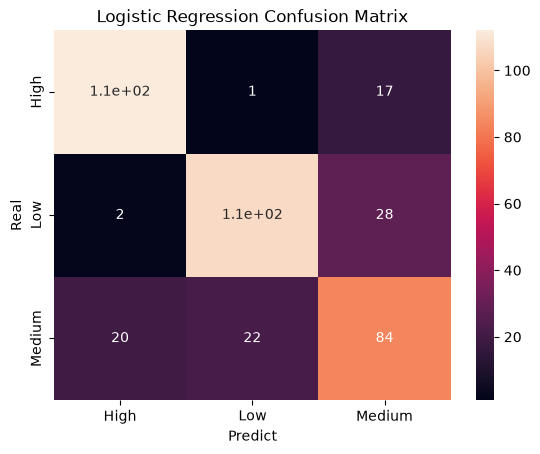

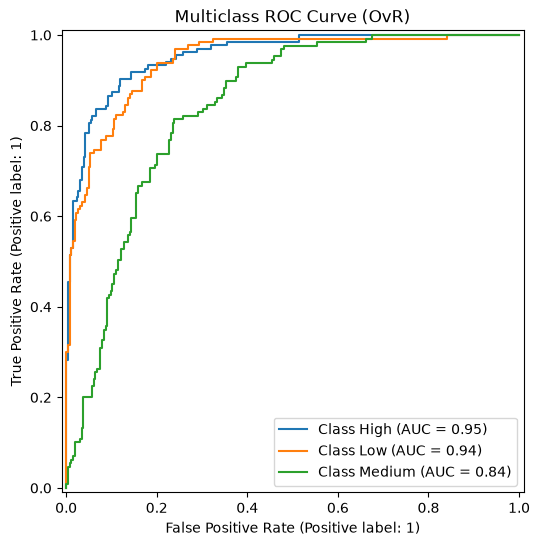

/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


	Support Vector Classifier
accuracy  : 72.52
precision : 72.39
recall    : 72.18
f1 score  : 72.27


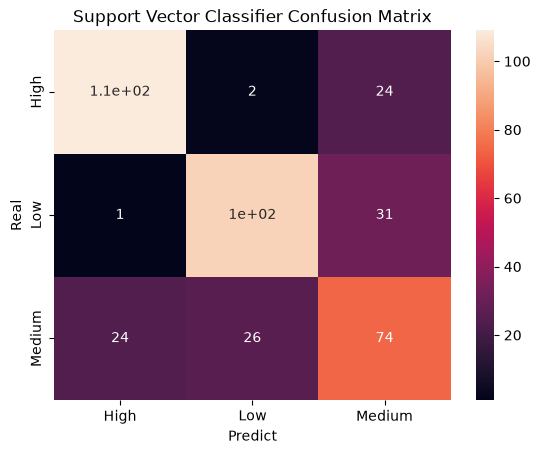

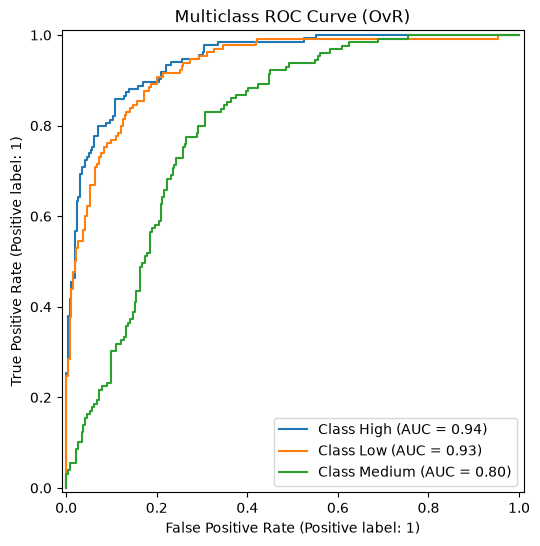

	KNN
accuracy  : 59.8
precision : 59.66
recall    : 58.33
f1 score  : 58.77


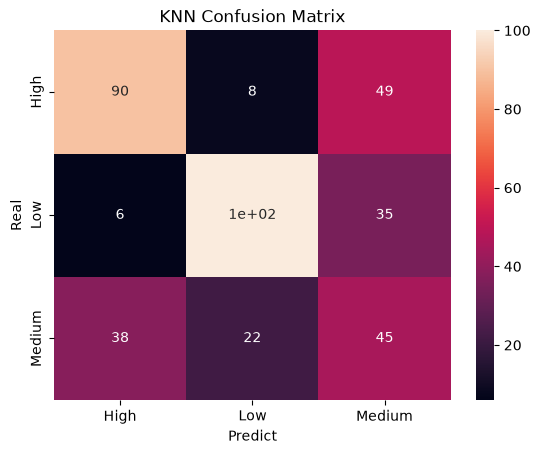

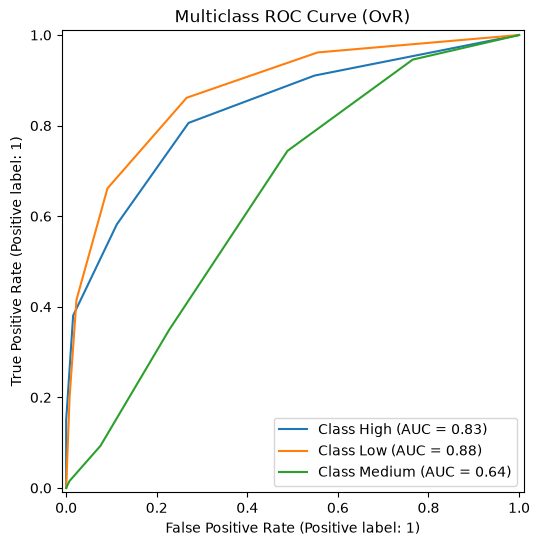

In [70]:
models = {
  'Logistic Regression'      : LogisticRegression(),
  'Support Vector Classifier': SVC(probability=True),
  'KNN'                      : KNeighborsClassifier()
}
default_models_metrics = []
# X_train,X_val,y_train,y_val = train_test_split(X_train,train_size=0.75,random_state=42,stratify=y)
for name,model in models.items():
  pipeline = Pipeline([
      ('preprocess',preprocess),
      ('model',model)
  ])
  model = pipeline.fit(X_train,y_train)
  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)
  classes_name = pipeline.classes_
  y_test_bin = label_binarize(y_test, classes=classes_name)
  accuracy = round(accuracy_score(y_pred,y_test)*100,2)
  precision = round(precision_score(y_pred,y_test,average='macro')*100,2)
  recall = round(recall_score(y_pred,y_test,average='macro')*100,2)
  f1 = round(f1_score(y_pred,y_test,average='macro')*100,2)
  auc = round(roc_auc_score(y_test,y_proba,multi_class="ovr",average="macro"),4)
  print('='*30)
  print(f'\t{name}')
  print('='*30)
  print('accuracy  :',accuracy)
  print('precision :',precision)
  print('recall    :',recall)
  print('f1 score  :',f1)
  default_models_metrics.append({'name':name,'accuracy':accuracy,'precision':precision,'recall':recall,'f1':f1,'auc':auc})
  cm = confusion_matrix(y_pred,y_test,labels=classes_name)
  sns.heatmap(cm,annot=True,xticklabels=classes_name,yticklabels=classes_name)
  plt.title(f'{name} Confusion Matrix')
  plt.xlabel('Predict')
  plt.ylabel('Real')
  plt.show()
  _,ax = plt.subplots(figsize=(8,6))
  for i, class_name in enumerate(classes_name):
    RocCurveDisplay.from_predictions(y_test_bin[:, i],y_proba[:, i],name=f"Class {class_name}",ax=ax)
  plt.title("Multiclass ROC Curve (OvR)")
  plt.show()
default_models_results = pd.DataFrame(default_models_metrics)

In [58]:
default_models_results

,name,accuracy,precision,recall,f1
0,Logistic Regression,77.10,77.00,76.97,76.96
1,Support Vector Classifier,72.52,72.39,72.18,72.27
2,KNN,59.80,59.66,58.33,58.77
